# Proyecto Integrador · Fase 3 (entrega final)
## Predicción del bajo peso al nacer en Colombia con datos reales del DANE
**Daniel Felipe Galeano Peña** · Machine Learning I · Universidad Externado de Colombia · Prof. Diana Pulido

**Artículo base:** Feyisa BR *et al.* (2023). *Nutrition, stress, and healthcare use during pregnancy are associated with low birth weight: evidence from a case–control study in West Ethiopia.* Front. Public Health 11:1213291.

**Datos:** Estadísticas Vitales (EEVV) del DANE, nacimientos 2022 (microdatos anonimizados, 573.625 registros; 567.766 con peso conocido, de los cuales el 10,48 % tiene bajo peso). Muestra aleatoria simple de 50.000 nacimientos (semilla 42), generada con `00_preparar_muestra.py`.

**Evento:** bajo peso al nacer (BPN) = peso < 2.500 g (códigos 1–4 de `PESO_NAC`).

**Cómo correr:** dejar `nacimientos_dane_2022_muestra.csv` en la carpeta `data/` (o junto al notebook) y ejecutar todo. Tarda unos 20–30 minutos (validación cruzada anidada de 9 modelos).

### Correcciones respecto a la segunda entrega
| Observación de la profesora | Qué se hizo en esta fase |
|---|---|
| Sin datos reales locales (simulación con efectos etíopes) | Todo el análisis usa microdatos reales del DANE 2022. La simulación se retira. |
| Comparación debía construirse con modelos del curso | Solo modelos vistos en clase: línea base, KNN, Naive Bayes, logística sin penalizar, LDA, QDA y logística regularizada (L2, L1, Elastic Net, Sesiones 37–38). |
| L1 y Elastic Net no fijaban `penalty`, así que eran L2 | Se fija `penalty="l1"` / `"elasticnet"` con `solver="saga"` (como en la Sesión 37b) y la sección 4.2 **verifica** que la L1 apaga coeficientes y la L2 no. |
| Sustentar qué hace la L2, por qué ese C y qué supuestos de LDA/QDA se cumplen | El C se elige por validación interna y se muestra su curva de validación (Fig. 2); los supuestos de LDA/QDA se discuten en la sección 4. |
| Tablas del informe distintas a las del cuaderno | Todas las tablas y figuras del informe se generan aquí y se guardan en `resultados/`. |
| Bibliografía incompleta y cuerpo de 9 páginas | Se corrige en el informe (3–5 páginas, referencias completas). |

In [1]:
import os, warnings, time
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_predict)
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, brier_score_loss,
                             recall_score, precision_score, fbeta_score, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)          # aviso de transición de la API 'penalty' (ver Sesión 37b)
warnings.filterwarnings("ignore", message=".*penalty.*")
warnings.filterwarnings("ignore", message=".*Variables are collinear.*")
SEED = 42
RES = "resultados/"; os.makedirs(RES, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


## 1. Datos y variables
**Variable objetivo (y):** bajo peso al nacer = 1 si el bebé pesó menos de 2.500 g (códigos 1–4 de `PESO_NAC`), 0 si pesó 2.500 g o más. Es la respuesta que el modelo aprende a predecir; por eso **no** está en la tabla de abajo: usarla como pista sería hacer trampa.

**Variables predictoras (X):** solo entran variables **conocidas antes del parto** (registradas por la madre o el control prenatal). Los códigos se convierten con reglas **fijas** tomadas del diccionario del DANE: no aprenden nada de los datos, por eso no generan fuga. Los "sin información" (9/99) se conservan como categoría propia.

| Variable | Columna DANE | Categorías |
|---|---|---|
| Edad de la madre | `EDAD_MADRE` | grupos quinquenales (10–14 … 45+) |
| Nivel educativo | `NIV_EDUM` | ninguno, primaria o menos, secundaria, media, técnica/tecnológica, profesional o posgrado |
| Zona de residencia | `AREA_RES` | cabecera, centro poblado, rural disperso |
| Régimen de salud | `SEG_SOCIAL` | contributivo, subsidiado, excepción/especial, no asegurado |
| Estado conyugal | `EST_CIVM` | unión libre ≥2 años, unión libre <2 años, separada/viuda, soltera, casada |
| Pertenencia étnica | `IDPERTET` | indígena, afrodescendiente, ninguna (Rrom, raizal y palenquera son muy pocos casos y se unen a "sin información") |
| Región de residencia | `CODPTORE` | Bogotá, Andina, Caribe, Pacífica, Orinoquía-Amazonía (regiones naturales) |
| Embarazo múltiple | `MUL_PARTO` | simple, múltiple |
| Paridad | `N_HIJOSV` (incluye al recién nacido) | primer hijo, segundo, tercero o más |
| Pérdidas previas | `N_EMB` > `N_HIJOSV` | sí, no |
| Controles prenatales | `NUMCONSUL` | < 4, 4–6, ≥ 7 |

**Excluidas por fuga** (se conocen al nacer o casi equivalen al desenlace): semanas de gestación, talla, Apgar, tipo de parto, quién atendió el parto, sitio del parto, sexo y grupo sanguíneo del recién nacido.

In [2]:
ruta = "data/nacimientos_dane_2022_muestra.csv"
if not os.path.exists(ruta):
    ruta = "nacimientos_dane_2022_muestra.csv"          # por si se sube suelto (Colab)
d = pd.read_csv(ruta, dtype=str)

REGION = {"11": "Bogota"}
REGION.update({c: "Caribe" for c in ["08", "13", "20", "23", "44", "47", "70", "88"]})
REGION.update({c: "Pacifica" for c in ["19", "27", "52", "76"]})
REGION.update({c: "Andina" for c in ["05", "15", "17", "25", "41", "54", "63", "66", "68", "73"]})
REGION.update({c: "Orinoquia_Amazonia" for c in ["18", "50", "81", "85", "86", "91", "94", "95", "97", "99"]})

def a_entero(s):
    return pd.to_numeric(s, errors="coerce")

def construir_X(d):
    nc, hv, ne = a_entero(d.NUMCONSUL), a_entero(d.N_HIJOSV), a_entero(d.N_EMB)
    hv_ok, ne_ok = hv.between(1, 30), ne.between(1, 30)
    return pd.DataFrame({
        "edad_madre": d.EDAD_MADRE.map({"1": "10-14", "2": "15-19", "3": "20-24", "4": "25-29", "5": "30-34",
                                        "6": "35-39", "7": "40-44", "8": "45+", "9": "45+"}).fillna("sin_info"),
        "educacion": d.NIV_EDUM.map({"13": "ninguno", "01": "primaria_o_menos", "02": "primaria_o_menos",
                                     "03": "secundaria", "04": "media", "05": "media", "06": "media",
                                     "07": "tecnica_tecnologica", "08": "tecnica_tecnologica",
                                     "09": "profesional_posgrado", "10": "profesional_posgrado",
                                     "11": "profesional_posgrado", "12": "profesional_posgrado"}).fillna("sin_info"),
        "zona": d.AREA_RES.map({"1": "cabecera", "2": "centro_poblado", "3": "rural_disperso"}).fillna("sin_info"),
        "regimen": d.SEG_SOCIAL.map({"1": "contributivo", "2": "subsidiado", "3": "excepcion_especial",
                                     "4": "excepcion_especial", "5": "no_asegurado"}).fillna("sin_info"),
        "estado_conyugal": d.EST_CIVM.map({"1": "union_libre_2mas", "2": "union_libre_menos2", "3": "separada_viuda",
                                           "4": "separada_viuda", "5": "soltera", "6": "casada"}).fillna("sin_info"),
        "etnia": d.IDPERTET.map({"1": "indigena", "5": "afrodescendiente", "6": "ninguna"}).fillna("otra_o_sin_info"),
        "region": d.CODPTORE.map(REGION).fillna("sin_info"),
        "embarazo_multiple": d.MUL_PARTO.map({"1": "simple", "2": "multiple", "3": "multiple",
                                              "4": "multiple"}).fillna("sin_info"),
        "paridad": np.select([~hv_ok, hv == 1, hv == 2], ["sin_info", "primer_hijo", "segundo"], "tercero_o_mas"),
        "perdidas_previas": np.select([~(hv_ok & ne_ok), ne > hv], ["sin_info", "si"], "no"),
        "controles": np.select([~nc.between(0, 60), nc < 4, nc <= 6], ["sin_info", "menos_4", "4_a_6"], "7_o_mas"),
    })

X = construir_X(d)
y = d.PESO_NAC.isin(list("1234")).astype(int).values
validos = d.PESO_NAC != "9"                         # peso sin información: no se puede etiquetar
X, y = X[validos.values].reset_index(drop=True), y[validos.values]
print(f"Registros con peso conocido: {len(y):,} | BPN: {y.sum():,} ({y.mean():.2%}) | Archivo completo DANE 2022: 10,48 % (567.766 con peso conocido)")

Registros con peso conocido: 49,523 | BPN: 5,159 (10.42%) | Archivo completo DANE 2022: 10,48 % (567.766 con peso conocido)


### 1.1 Tasa de BPN por categoría (descriptivo, toda la muestra)
Es solo una primera mirada (sin ajustar por las demás variables). Se usa para entender el problema, no para elegir variables.

In [3]:
filas = []
for v in X.columns:
    g = pd.DataFrame({"cat": X[v], "y": y}).groupby("cat").y.agg(["count", "mean"])
    for cat, r in g.iterrows():
        filas.append({"variable": v, "categoria": cat, "n": int(r["count"]), "tasa_BPN_%": round(100 * r["mean"], 1)})
descr = pd.DataFrame(filas)
descr.to_csv(RES + "tabla1_descriptivo.csv", index=False)
print(descr[descr.categoria != "sin_info"].to_string(index=False))

         variable            categoria     n  tasa_BPN_%
       edad_madre                10-14   369        17.1
       edad_madre                15-19  8001        11.3
       edad_madre                20-24 13624         9.9
       edad_madre                25-29 12654         9.6
       edad_madre                30-34  8805        10.1
       edad_madre                35-39  4699        11.8
       edad_madre                40-44  1295        13.7
       edad_madre                  45+    76        11.8
        educacion                media 18124        10.6
        educacion              ninguno   506        11.5
        educacion     primaria_o_menos  5554        11.0
        educacion profesional_posgrado  6538        10.2
        educacion           secundaria 10757        10.0
        educacion  tecnica_tecnologica  6756        10.0
             zona             cabecera 37115        10.7
             zona       centro_poblado  3614         8.3
             zona       rural_d

**Lectura de la Tabla 1.** El 10,4 % de los nacimientos de la muestra tiene bajo peso, prácticamente igual al 10,5 % del archivo completo del DANE de 2022: la muestra es representativa y la variable quedó bien construida. Sin ajustar por nada, las diferencias grandes están en pocas variables: embarazo múltiple (69,6 % frente a 9,3 % en simples), controles prenatales (15,0 % con menos de 4 frente a 7,6 % con 7 o más), región (15,3 % en Bogotá frente a 7,2 % en Orinoquía-Amazonía) y edades extremas de la madre (17,1 % a los 10–14 años, 13,7 % a los 40–44). Educación, zona y régimen de salud apenas mueven la tasa (entre 8 % y 11 %).

## 2. Partición y flujo sin fuga
* **80 / 20 estratificado** (semilla 42). El 20 % de prueba se toca **una sola vez**, al final, y solo con el modelo elegido.
* Cada modelo es **un solo `Pipeline`**: `OneHotEncoder` (aprende las categorías solo del entrenamiento; las categorías nuevas se ignoran) → `StandardScaler` cuando el modelo lo necesita → modelo.
* **Validación cruzada anidada**: por fuera 5 pliegues × 2 repeticiones (10 estimaciones para medir **estabilidad**); por dentro `GridSearchCV` de 3 pliegues elige los hiperparámetros optimizando **PR-AUC** (la métrica correcta con ~10 % de casos: la exactitud de "nadie tiene BPN" ya sería 90 %).

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Entrenamiento: {len(ytr):,} ({ytr.mean():.2%} BPN) | Prueba: {len(yte):,} ({yte.mean():.2%} BPN)")

def tuberia(modelo, escalar=False):
    pasos = [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    if escalar:
        pasos.append(("escala", StandardScaler()))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

REJILLA_C = [0.001, 0.01, 0.1, 1, 10]
ESPECS = {   # nombre: (tubería, rejilla de hiperparámetros)
    "Línea base (prevalencia)": (tuberia(DummyClassifier(strategy="prior")), None),
    "KNN": (tuberia(KNeighborsClassifier(algorithm="brute")), {"modelo__n_neighbors": [51, 101, 201, 401]}),
    "Naive Bayes (Bernoulli)": (tuberia(BernoulliNB()), {"modelo__alpha": [0.1, 1.0]}),
    "LDA": (tuberia(LinearDiscriminantAnalysis()), None),
    "QDA": (tuberia(QuadraticDiscriminantAnalysis(), escalar=True), {"modelo__reg_param": [0.01, 0.1, 0.5]}),
    "Logística sin penalizar": (tuberia(LogisticRegression(penalty=None, max_iter=5000), escalar=True), None),
    "Logística L2 (Ridge)": (tuberia(LogisticRegression(penalty="l2", max_iter=5000), escalar=True),
                             {"modelo__C": REJILLA_C}),
    "Logística L1 (Lasso)": (tuberia(LogisticRegression(penalty="l1", solver="saga", tol=1e-3, max_iter=5000), escalar=True),
                             {"modelo__C": REJILLA_C}),
    "Elastic Net (α=0,5)": (tuberia(LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, tol=1e-3,
                                                         max_iter=5000), escalar=True), {"modelo__C": REJILLA_C}),
}
def estimador(nombre):
    tub, rej = ESPECS[nombre]
    tub = clone(tub)
    return GridSearchCV(tub, rej, scoring="average_precision", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                        n_jobs=1) if rej else tub

Entrenamiento: 39,618 (10.42% BPN) | Prueba: 9,905 (10.42% BPN)


**Por qué cada decisión de preprocesamiento:**
* **KNN y Naive Bayes sin escalar:** tras el one-hot todas las columnas son 0/1, ya están en la misma escala. Escalar haría pesar más las categorías raras en la distancia. Para Naive Bayes se usa la versión **Bernoulli**, que es la que corresponde a variables binarias (la gaussiana supondría variables continuas normales).
* **Logísticas y QDA escalados:** la penalización castiga el tamaño de los coeficientes, así que todas las columnas deben estar en la misma escala para que el castigo sea justo (Sesión 37). En QDA el `reg_param` también depende de la escala.
* **LDA sin escalar:** su frontera no cambia con la escala.
* **QDA con `reg_param`:** con variables 0/1 y categorías raras, la covarianza de cada clase es casi singular; sin regularizarla QDA no se puede estimar.

## 3. Validación cruzada anidada: comparación y estabilidad

In [5]:
cv_ext = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
METRICAS = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "brier": "neg_brier_score"}
por_pliegue, elegidos = [], {}
for nombre in ESPECS:
    t0 = time.time()
    r = cross_validate(estimador(nombre), Xtr, ytr, cv=cv_ext, scoring=METRICAS, return_estimator=True)
    for k in range(len(r["test_pr_auc"])):
        por_pliegue.append({"modelo": nombre, "pliegue": k + 1, "PR-AUC": r["test_pr_auc"][k],
                            "ROC-AUC": r["test_roc_auc"][k], "Brier": -r["test_brier"][k]})
    elegidos[nombre] = [str(e.best_params_) if hasattr(e, "best_params_") else "-" for e in r["estimator"]]
    print(f"{nombre:28s} PR-AUC = {r['test_pr_auc'].mean():.3f} ± {r['test_pr_auc'].std():.3f}   ({time.time()-t0:.0f} s)")

pp = pd.DataFrame(por_pliegue); pp.to_csv(RES + "cv_por_pliegue.csv", index=False)
tabla_cv = (pp.groupby("modelo", sort=False)
              .agg(PR_AUC_media=("PR-AUC", "mean"), PR_AUC_de=("PR-AUC", "std"),
                   ROC_AUC_media=("ROC-AUC", "mean"), ROC_AUC_de=("ROC-AUC", "std"),
                   Brier_media=("Brier", "mean")).round(4).reset_index())
tabla_cv["hiperparámetro más elegido"] = [pd.Series(elegidos[m]).mode()[0] for m in tabla_cv.modelo]
tabla_cv.to_csv(RES + "tabla2_comparacion_cv.csv", index=False)
print(tabla_cv.to_string(index=False))

Línea base (prevalencia)     PR-AUC = 0.104 ± 0.000   (1 s)


KNN                          PR-AUC = 0.203 ± 0.011   (129 s)


Naive Bayes (Bernoulli)      PR-AUC = 0.264 ± 0.013   (7 s)


LDA                          PR-AUC = 0.273 ± 0.012   (2 s)


QDA                          PR-AUC = 0.243 ± 0.012   (17 s)


Logística sin penalizar      PR-AUC = 0.273 ± 0.011   (2 s)


Logística L2 (Ridge)         PR-AUC = 0.273 ± 0.011   (18 s)


Logística L1 (Lasso)         PR-AUC = 0.274 ± 0.012   (330 s)


Elastic Net (α=0,5)          PR-AUC = 0.273 ± 0.012   (183 s)
                  modelo  PR_AUC_media  PR_AUC_de  ROC_AUC_media  ROC_AUC_de  Brier_media   hiperparámetro más elegido
Línea base (prevalencia)        0.1042     0.0001         0.5000      0.0000       0.0933                            -
                     KNN        0.2025     0.0121         0.6442      0.0090       0.0913 {'modelo__n_neighbors': 401}
 Naive Bayes (Bernoulli)        0.2643     0.0140         0.6638      0.0088       0.0871       {'modelo__alpha': 0.1}
                     LDA        0.2733     0.0122         0.6747      0.0085       0.0872                            -
                     QDA        0.2427     0.0125         0.6542      0.0111       0.1131   {'modelo__reg_param': 0.5}
 Logística sin penalizar        0.2733     0.0121         0.6746      0.0092       0.0851                            -
    Logística L2 (Ridge)        0.2733     0.0121         0.6746      0.0092       0.0851           {'mod

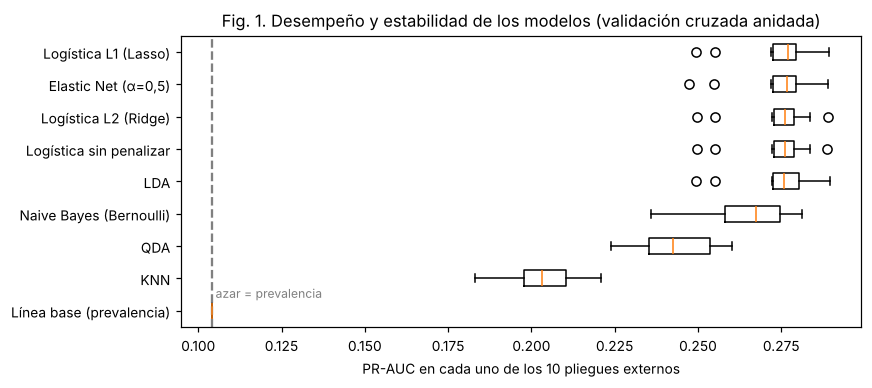

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
orden = tabla_cv.sort_values("PR_AUC_media").modelo.tolist()
datos_box = [pp[pp.modelo == m]["PR-AUC"] for m in orden]
try:
    ax.boxplot(datos_box, orientation="horizontal")      # matplotlib >= 3.10
except TypeError:
    ax.boxplot(datos_box, vert=False)                    # versiones anteriores
ax.set_yticks(range(1, len(orden) + 1)); ax.set_yticklabels(orden)
ax.axvline(ytr.mean(), ls="--", c="gray"); ax.text(ytr.mean(), 1.4, " azar = prevalencia", color="gray", fontsize=8)
ax.set_xlabel("PR-AUC en cada uno de los 10 pliegues externos")
ax.set_title("Fig. 1. Desempeño y estabilidad de los modelos (validación cruzada anidada)")
plt.tight_layout(); plt.savefig(RES + "fig1_estabilidad_cv.png", dpi=200); plt.show()

**Lectura de la Tabla 2 y la Fig. 1.** Las cuatro logísticas y LDA quedan prácticamente empatadas (PR-AUC 0,273–0,274, unas 2,6 veces el azar de 0,104) y son estables: su PR-AUC varía ±0,012 entre pliegues. Entre ellas, la diferencia máxima (0,0003) es unas 40 veces menor que esa variación, así que no son distinguibles. Naive Bayes queda un poco por debajo (0,264) y es más variable; QDA (0,243) y KNN (0,203) son claramente peores. En calibración (Brier, menor es mejor) las logísticas son las mejores (0,0851); QDA (0,1131) es peor incluso que la línea base (0,0933): sus probabilidades no son confiables.

### 3.1 Regla de selección (fijada antes de mirar los resultados)
1. Se toma el modelo con mayor PR-AUC media en la validación cruzada.
2. Se consideran **empatados** con él todos los modelos cuya PR-AUC media esté a menos de **una desviación estándar** del mejor (regla de "una desviación estándar"): diferencias más pequeñas que la variación entre pliegues no son confiables.
3. Entre los empatados se elige el **más interpretable**, en este orden: logística sin penalizar (odds ratios directos, el mismo método del artículo) → L1 → L2 → Elastic Net → LDA → Naive Bayes → KNN → QDA. Desempate final: menor Brier (mejor calibración).

In [7]:
ORDEN_INTERP = ["Logística sin penalizar", "Logística L1 (Lasso)", "Logística L2 (Ridge)", "Elastic Net (α=0,5)",
                "LDA", "Naive Bayes (Bernoulli)", "KNN", "QDA"]
t = tabla_cv.set_index("modelo")
mejor = t.drop("Línea base (prevalencia)").PR_AUC_media.idxmax()
umbral_empate = t.loc[mejor, "PR_AUC_media"] - t.loc[mejor, "PR_AUC_de"]
empatados = [m for m in ORDEN_INTERP if t.loc[m, "PR_AUC_media"] >= umbral_empate]
FINAL = empatados[0]
print(f"Mejor PR-AUC media: {mejor} ({t.loc[mejor,'PR_AUC_media']:.4f} ± {t.loc[mejor,'PR_AUC_de']:.4f})")
print(f"Empatados (≥ {umbral_empate:.4f}): {empatados}")
print(f"MODELO FINAL: {FINAL}")

Mejor PR-AUC media: Logística L1 (Lasso) (0.2736 ± 0.0123)
Empatados (≥ 0.2613): ['Logística sin penalizar', 'Logística L1 (Lasso)', 'Logística L2 (Ridge)', 'Elastic Net (α=0,5)', 'LDA', 'Naive Bayes (Bernoulli)']
MODELO FINAL: Logística sin penalizar


**Decisión.** El mejor promedio lo tiene la L1, pero la logística sin penalizar está dentro de una desviación estándar y es la más interpretable (da odds ratios directos, el mismo método del artículo) y la mejor calibrada junto con las otras logísticas. Por la regla fijada antes, el **modelo final es la logística sin penalizar**: no es el más complejo, es el de mejor equilibrio entre desempeño, estabilidad e interpretabilidad.

## 4. Qué hacen la regularización y el análisis discriminante en este problema
### 4.1 Curvas de validación: ¿qué C elige la validación interna?
`C` es el inverso de la fuerza de penalización: C pequeño = castigo fuerte (coeficientes más cerca de 0); C grande = casi sin penalizar.

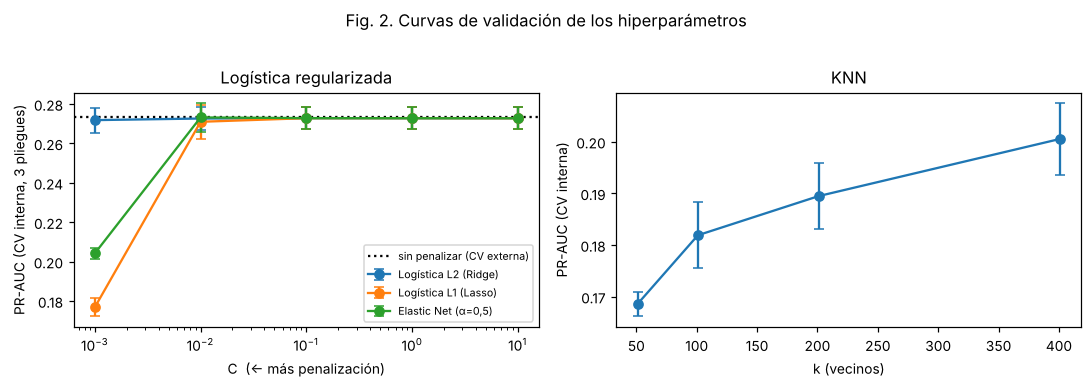

In [8]:
curvas = {}
for nombre, par in [("Logística L2 (Ridge)", "modelo__C"), ("Logística L1 (Lasso)", "modelo__C"),
                    ("Elastic Net (α=0,5)", "modelo__C"), ("KNN", "modelo__n_neighbors")]:
    g = estimador(nombre).fit(Xtr, ytr)
    curvas[nombre] = pd.DataFrame({"valor": g.cv_results_["param_" + par].data.astype(float),
                                   "media": g.cv_results_["mean_test_score"], "de": g.cv_results_["std_test_score"]})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for nombre in ["Logística L2 (Ridge)", "Logística L1 (Lasso)", "Elastic Net (α=0,5)"]:
    c = curvas[nombre]; ax[0].errorbar(c.valor, c.media, yerr=c.de, marker="o", capsize=3, label=nombre)
ax[0].axhline(t.loc["Logística sin penalizar", "PR_AUC_media"], ls=":", c="k", label="sin penalizar (CV externa)")
ax[0].set(xscale="log", xlabel="C  (← más penalización)", ylabel="PR-AUC (CV interna, 3 pliegues)",
          title="Logística regularizada"); ax[0].legend(fontsize=7)
c = curvas["KNN"]; ax[1].errorbar(c.valor, c.media, yerr=c.de, marker="o", capsize=3)
ax[1].set(xlabel="k (vecinos)", ylabel="PR-AUC (CV interna)", title="KNN")
fig.suptitle("Fig. 2. Curvas de validación de los hiperparámetros", y=1.02)
plt.tight_layout(); plt.savefig(RES + "fig2_curvas_validacion.png", dpi=200, bbox_inches="tight"); plt.show()
pd.concat({k: v for k, v in curvas.items()}).round(4).to_csv(RES + "curvas_validacion.csv")

**Lectura de la Fig. 2.** Con C de 0,01 hacia arriba, L2, L1 y Elastic Net dan la misma PR-AUC que el modelo sin penalizar; solo con C = 0,001 (castigo muy fuerte) se pierde desempeño, porque la penalización apaga casi todas las variables. La razón: hay unos 40.000 registros para estimar 54 coeficientes, así que los coeficientes ya son estables y la regularización no tiene varianza que reducir. La validación interna eligió C = 0,1, en plena meseta. **Conclusión:** aquí regularizar no mejora nada, y por eso no justifica perder la lectura directa de los odds ratios. En KNN el desempeño sube con k (el mejor fue k = 401, el borde de la rejilla): con variables categóricas hay muchos registros idénticos y KNN termina promediando grupos grandes, es decir, se acerca a un modelo más simple; aun así queda lejos (0,203).

### 4.2 Verificación: la L1 de verdad es L1 (corrección del error de la segunda entrega)
Con el mismo C, la **L1** debe dejar coeficientes **exactamente en cero** (selección de variables) y la **L2** solo encogerlos. Si las dos dieran lo mismo, la penalización no estaría bien fijada.

In [9]:
Xtr_esc = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                    ("escala", StandardScaler())]).fit(Xtr)
nombres_col = Xtr_esc.named_steps["onehot"].get_feature_names_out()
Z = Xtr_esc.transform(Xtr)
filas = []
for C in [0.001, 0.01, 0.1, 1]:
    l1 = LogisticRegression(penalty="l1", solver="saga", C=C, tol=1e-3, max_iter=5000).fit(Z, ytr).coef_[0]
    l2 = LogisticRegression(penalty="l2", C=C, max_iter=5000).fit(Z, ytr).coef_[0]
    filas.append({"C": C, "coef. en cero L1": int((l1 == 0).sum()), "coef. en cero L2": int((l2 == 0).sum()),
                  "norma L1 de β (L1)": round(np.abs(l1).sum(), 3), "norma L1 de β (L2)": round(np.abs(l2).sum(), 3)})
verif = pd.DataFrame(filas); verif.to_csv(RES + "verificacion_L1_L2.csv", index=False)
print(f"Total de coeficientes: {len(nombres_col)}"); print(verif.to_string(index=False))

Total de coeficientes: 54
    C  coef. en cero L1  coef. en cero L2  norma L1 de β (L1)  norma L1 de β (L2)
0.001                52                 0               0.322               1.964
0.010                33                 0               1.512               2.526
0.100                 7                 0               2.382               2.672
1.000                 3                 0               2.606               2.698


**Lectura.** Con el mismo C = 0,01 la L1 deja 33 de los 54 coeficientes exactamente en cero y la L2 ninguno; con C = 0,001 la L1 apaga 52. Las dos penalizaciones ahora hacen cosas distintas, como deben: el error de la segunda entrega (L1 y Elastic Net que en realidad eran L2) quedó corregido.

### 4.3 Supuestos de LDA y QDA
LDA y QDA suponen que, dentro de cada clase, las variables siguen una **normal multivariada** (LDA además supone la **misma covarianza** en las dos clases). Aquí todas las variables son indicadores 0/1, así que la normalidad **no se cumple** por construcción. Abajo se revisa el supuesto de covarianzas iguales comparando la varianza de cada indicador en las dos clases.

In [10]:
O = pd.DataFrame(Xtr_esc.named_steps["onehot"].transform(Xtr), columns=nombres_col)
var0, var1 = O[ytr == 0].var(), O[ytr == 1].var()
razon = (var1 / var0.replace(0, np.nan)).dropna()
print(f"Razón de varianzas (BPN / no BPN) por indicador: mediana {razon.median():.2f}, "
      f"mín {razon.min():.2f}, máx {razon.max():.2f}")
print("Indicadores con varianza al menos 2 veces distinta entre clases:",
      list(razon[(razon > 2) | (razon < 0.5)].index))

Razón de varianzas (BPN / no BPN) por indicador: mediana 1.01, mín 0.00, máx 17.73
Indicadores con varianza al menos 2 veces distinta entre clases: ['regimen_sin_info', 'etnia_otra_o_sin_info', 'embarazo_multiple_multiple', 'embarazo_multiple_simple', 'embarazo_multiple_sin_info', 'paridad_sin_info', 'perdidas_previas_sin_info']


**Lectura.** La normalidad no se cumple por construcción (variables 0/1). El supuesto de covarianzas iguales de LDA es razonable para casi todos los indicadores (la razón de varianzas tiene mediana 1,01), pero falla en embarazo múltiple, cuya varianza es unas 18 veces mayor entre los casos de BPN. Aun así LDA discrimina igual que la logística, porque ambas terminan en una frontera lineal parecida; lo que se resiente es la calibración (Brier 0,0872 frente a 0,0851), que sí depende del supuesto normal. QDA estima una matriz de covarianza distinta por clase con solo unos 4.100 casos de BPN en entrenamiento y 54 columnas binarias: sin `reg_param` no se puede estimar, la validación eligió una regularización fuerte (0,5) y aun así es el modelo peor calibrado. Por eso LDA y QDA quedan como **comparación declarada**, no como modelo final.

## 5. Modelo final: configuración, umbral y evaluación única en prueba
* Se ajusta el modelo elegido sobre **todo** el 80 % de entrenamiento.
* **Umbral de decisión:** se elige el que maximiza **F2** (pesa el recall el doble que la precisión: en salud pública es más grave no detectar un caso que dar una alarma de más), usando predicciones **fuera de muestra** del entrenamiento (`cross_val_predict`), nunca la prueba.

In [11]:
def umbral_f2(yv, s):
    p, r, u = precision_recall_curve(yv, s)
    f2 = 5 * p[:-1] * r[:-1] / np.maximum(4 * p[:-1] + r[:-1], 1e-12)
    return u[int(np.argmax(f2))]

final = estimador(FINAL).fit(Xtr, ytr)
config = final.best_params_ if hasattr(final, "best_params_") else "sin hiperparámetros que ajustar"
oof = cross_val_predict(estimador(FINAL), Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                        method="predict_proba")[:, 1]
UMBRAL = umbral_f2(ytr, oof)
print(f"Modelo final: {FINAL} | configuración: {config} | umbral F2 (fuera de muestra): {UMBRAL:.4f}")

Modelo final: Logística sin penalizar | configuración: sin hiperparámetros que ajustar | umbral F2 (fuera de muestra): 0.0817


In [12]:
# ===== ÚNICA evaluación sobre el conjunto de prueba =====
s_te = final.predict_proba(Xte)[:, 1]
pred = (s_te >= UMBRAL).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    b = rng.integers(0, len(yte), len(yte))
    boot.append((average_precision_score(yte[b], s_te[b]), roc_auc_score(yte[b], s_te[b])))
boot = np.array(boot)
res_prueba = pd.DataFrame([
    ("PR-AUC", average_precision_score(yte, s_te), *np.percentile(boot[:, 0], [2.5, 97.5])),
    ("PR-AUC del azar (prevalencia)", yte.mean(), np.nan, np.nan),
    ("ROC-AUC", roc_auc_score(yte, s_te), *np.percentile(boot[:, 1], [2.5, 97.5])),
    ("Brier", brier_score_loss(yte, s_te), np.nan, np.nan),
    ("Brier de la línea base", brier_score_loss(yte, np.full(len(yte), ytr.mean())), np.nan, np.nan),
    ("Umbral (F2, fuera de muestra)", UMBRAL, np.nan, np.nan),
    ("Recall (sensibilidad)", tp / (tp + fn), np.nan, np.nan),
    ("Precisión (VPP)", tp / (tp + fp), np.nan, np.nan),
    ("Especificidad", tn / (tn + fp), np.nan, np.nan),
    ("F2", fbeta_score(yte, pred, beta=2), np.nan, np.nan),
    ("% de nacimientos marcados en riesgo", pred.mean(), np.nan, np.nan),
], columns=["métrica", "valor", "IC95 inf", "IC95 sup"]).round(4)
res_prueba.to_csv(RES + "tabla3_prueba_final.csv", index=False)
print(res_prueba.to_string(index=False))
mc = pd.DataFrame([[tn, fp], [fn, tp]], index=["real: sin BPN", "real: BPN"], columns=["predicho: sin BPN", "predicho: BPN"])
mc.to_csv(RES + "matriz_confusion.csv"); print("\nMatriz de confusión (prueba):\n", mc)

                            métrica  valor  IC95 inf  IC95 sup
                             PR-AUC 0.2664    0.2404    0.2924
      PR-AUC del azar (prevalencia) 0.1042       NaN       NaN
                            ROC-AUC 0.6630    0.6454    0.6809
                              Brier 0.0858       NaN       NaN
             Brier de la línea base 0.0933       NaN       NaN
      Umbral (F2, fuera de muestra) 0.0817       NaN       NaN
              Recall (sensibilidad) 0.7016       NaN       NaN
                    Precisión (VPP) 0.1415       NaN       NaN
                      Especificidad 0.5048       NaN       NaN
                                 F2 0.3915       NaN       NaN
% de nacimientos marcados en riesgo 0.5167       NaN       NaN

Matriz de confusión (prueba):
                predicho: sin BPN  predicho: BPN
real: sin BPN               4479           4394
real: BPN                    308            724


**Lectura de la Tabla 3.** En la prueba (tocada una sola vez) la PR-AUC es 0,266 (IC 95 %: 0,240–0,292), 2,6 veces el azar (0,104), y muy cercana a la de validación cruzada (0,273): **no hay sobreajuste**. La ROC-AUC es 0,663: si se toma al azar un bebé con BPN y uno sin BPN, el modelo le da más riesgo al primero dos de cada tres veces. El Brier (0,0858) mejora el de la línea base (0,0933). Con el umbral F2 (0,082), el modelo detecta el **70 % de los casos** (724 de 1.032), pero para lograrlo marca al 52 % de los nacimientos: de cada 100 madres marcadas, 14 tienen un bebé con BPN (frente a 10 sin modelo).

### 5.1 Matriz de confusión, calibración y priorización por riesgo

                   nacimientos  casos_BPN  tasa_observada  riesgo_predicho_medio  % de todos los casos
quintil de riesgo                                                                                     
1                         1981        116          0.0586                 0.0471               11.2403
2                         1981        119          0.0601                 0.0658               11.5310
3                         1981        178          0.0899                 0.0845               17.2481
4                         1981        217          0.1095                 0.1110               21.0271
5                         1981        402          0.2029                 0.2075               38.9535


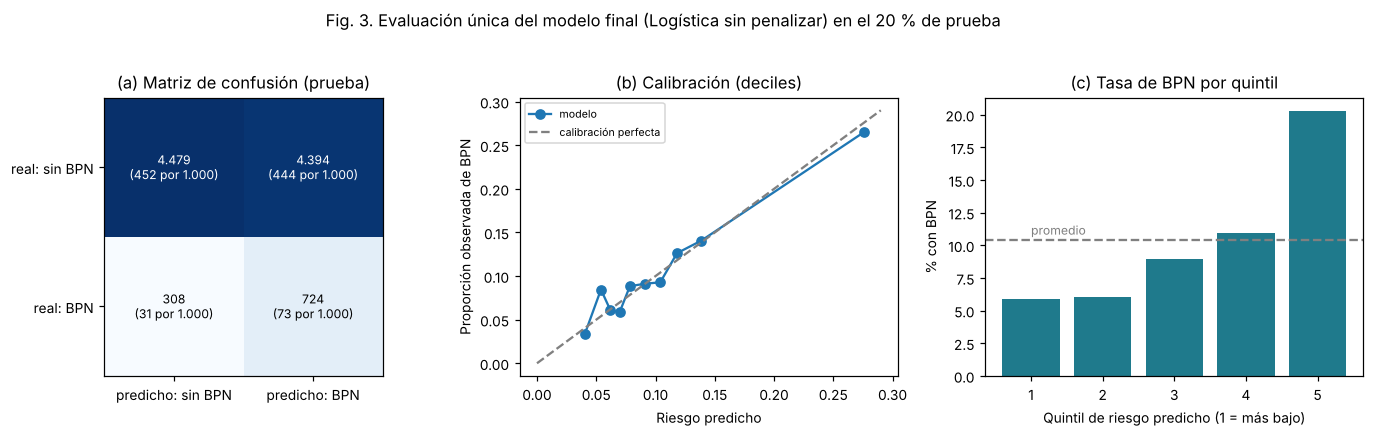

In [13]:
q = pd.qcut(pd.Series(s_te).rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
quint = (pd.DataFrame({"quintil de riesgo": q, "y": yte, "s": s_te}).groupby("quintil de riesgo", observed=True)
           .agg(nacimientos=("y", "size"), casos_BPN=("y", "sum"), tasa_observada=("y", "mean"), riesgo_predicho_medio=("s", "mean")))
quint["% de todos los casos"] = 100 * quint.casos_BPN / quint.casos_BPN.sum()
quint = quint.round(4); quint.to_csv(RES + "tabla4_quintiles_riesgo.csv"); print(quint.to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
mc_mil = (mc / len(yte) * 1000).round(0).astype(int)
ax[0].imshow(mc.values, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{mc.values[i, j]:,}".replace(",", ".") + f"\n({mc_mil.values[i, j]} por 1.000)",
                   ha="center", va="center", fontsize=8, color="white" if mc.values[i, j] > mc.values.max() / 2 else "black")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(mc.columns); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(mc.index)
ax[0].set_title("(a) Matriz de confusión (prueba)")
fp_, mp_ = calibration_curve(yte, s_te, n_bins=10, strategy="quantile")
ax[1].plot(mp_, fp_, "o-", label="modelo"); lim = max(mp_.max(), fp_.max()) * 1.05
ax[1].plot([0, lim], [0, lim], "--", c="gray", label="calibración perfecta")
ax[1].set(xlabel="Riesgo predicho", ylabel="Proporción observada de BPN", title="(b) Calibración (deciles)"); ax[1].legend(fontsize=7)
ax[2].bar(quint.index.astype(str), 100 * quint.tasa_observada, color="#1F7A8C")
ax[2].axhline(100 * yte.mean(), ls="--", c="gray"); ax[2].text(0, 100 * yte.mean() + 0.4, "promedio", color="gray", fontsize=8)
ax[2].set(xlabel="Quintil de riesgo predicho (1 = más bajo)", ylabel="% con BPN", title="(c) Tasa de BPN por quintil")
fig.suptitle(f"Fig. 3. Evaluación única del modelo final ({FINAL}) en el 20 % de prueba", y=1.03)
plt.tight_layout(); plt.savefig(RES + "fig3_prueba_final.png", dpi=200, bbox_inches="tight"); plt.show()

**Lectura de la Fig. 3.** (a) Por cada 1.000 nacimientos, el modelo detecta 73 casos, deja pasar 31, da 444 falsas alarmas y descarta bien 452. En este problema los dos errores no cuestan lo mismo: un **falso negativo** es un bebé de bajo peso cuya madre no recibió vigilancia extra (el BPN es la principal causa de muerte neonatal); un **falso positivo** es un control o una ecografía de crecimiento de más. Por eso se aceptan muchas falsas alarmas. (b) Los puntos siguen la diagonal: cuando el modelo dice "15 % de riesgo", en la realidad ocurre cerca del 15 %, así que las probabilidades son creíbles. (c) El quintil de mayor riesgo tiene 20,3 % de BPN (el doble del promedio) y concentra el 39 % de todos los casos con solo el 20 % de los nacimientos; el de menor riesgo, 5,9 %. Un uso realista es **priorizar**: concentrar seguimiento en el 20 % de mayor riesgo en vez de marcar a la mitad.

### 5.2 ¿A quién no detecta el modelo? (análisis de errores)
Se compara el perfil de los casos de BPN **detectados** (verdaderos positivos) con los **no detectados** (falsos negativos).

In [14]:
casos = Xte[yte == 1].copy(); casos["detectado"] = np.where(pred[yte == 1] == 1, "detectado (VP)", "no detectado (FN)")
perfil = pd.DataFrame({
    "% embarazo múltiple": casos.groupby("detectado").embarazo_multiple.apply(lambda s: 100 * (s == "multiple").mean()),
    "% < 4 controles": casos.groupby("detectado").controles.apply(lambda s: 100 * (s == "menos_4").mean()),
    "% ≥ 7 controles": casos.groupby("detectado").controles.apply(lambda s: 100 * (s == "7_o_mas").mean()),
    "% residentes en Bogotá": casos.groupby("detectado").region.apply(lambda s: 100 * (s == "Bogota").mean()),
    "% madres 35+ años": casos.groupby("detectado").edad_madre.apply(lambda s: 100 * s.isin(["35-39", "40-44", "45+"]).mean()),
    "n": casos.groupby("detectado").size(),
}).round(1)
perfil.to_csv(RES + "tabla5_perfil_errores.csv"); print(perfil.T)

detectado               detectado (VP)  no detectado (FN)
% embarazo múltiple               15.9                0.0
% < 4 controles                   28.5                2.3
% ≥ 7 controles                   18.1               76.9
% residentes en Bogotá            21.0                4.2
% madres 35+ años                 16.3                9.4
n                                724.0              308.0


**Lectura de la Tabla 5.** Los casos no detectados casi nunca tienen un factor visible en el registro: ninguno es embarazo múltiple, solo el 2,3 % tuvo menos de 4 controles y el 77 % tuvo 7 o más. El modelo encuentra el BPN que deja huella en el certificado (gemelos, pocos controles, Bogotá, edades extremas) y no ve el que ocurre en embarazos aparentemente bien controlados, cuyas causas (preeclampsia, insuficiencia placentaria, desnutrición o estrés materno, tabaquismo) **no se registran** en las estadísticas vitales. Ese es el límite del modelo, no del algoritmo.

## 6. Interpretación: odds ratios ajustados y contraste con el artículo
Se ajusta la misma logística sin penalizar con `statsmodels` sobre el 80 % de entrenamiento para obtener **intervalos de confianza** (el mismo método del artículo: regresión logística multivariable). Categoría de referencia = la más frecuente de cada variable (regla fijada de antemano). Las categorías "sin información" se mantienen en el modelo pero no se interpretan.

In [15]:
def tabla_or(Xa, ya, columnas):
    D = pd.get_dummies(Xa[columnas], dtype=float)
    refs = [Xa[c].value_counts().idxmax() for c in columnas]
    refs = [f"{c}_{r}" for c, r in zip(columnas, refs)]
    D = D.drop(columns=refs).loc[:, lambda z: z.sum() > 0]
    D = D.T.drop_duplicates().T                       # 'sin_info' que coinciden en los mismos registros
    D = D.loc[:, [c for c in D.columns if ya[D[c].values == 1].sum() > 0]]   # categorías sin ningún caso: no estimables
    m = sm.Logit(ya, sm.add_constant(D)).fit(disp=0, maxiter=300)
    ci = np.exp(m.conf_int())
    out = pd.DataFrame({"OR": np.exp(m.params), "IC95 inf": ci[0], "IC95 sup": ci[1], "p": m.pvalues}).drop("const")
    out = out[~out.index.str.contains("sin_info")]
    return out.round(3), refs

OR_tab, refs = tabla_or(Xtr, ytr, list(X.columns))
print("Referencias:", refs)
OR_tab.sort_values("OR", ascending=False).to_csv(RES + "tabla6_odds_ratios.csv")
print(OR_tab.sort_values("OR", ascending=False).to_string())

Referencias: ['edad_madre_20-24', 'educacion_media', 'zona_cabecera', 'regimen_subsidiado', 'estado_conyugal_union_libre_2mas', 'etnia_ninguna', 'region_Andina', 'embarazo_multiple_simple', 'paridad_primer_hijo', 'perdidas_previas_no', 'controles_7_o_mas']
                                        OR  IC95 inf  IC95 sup      p
embarazo_multiple_multiple          29.712    25.003    35.308  0.000
controles_menos_4                    3.009     2.707     3.345  0.000
controles_4_a_6                      1.928     1.780     2.088  0.000
edad_madre_40-44                     1.779     1.444     2.191  0.000
region_Bogota                        1.490     1.342     1.654  0.000
edad_madre_45+                       1.488     0.633     3.499  0.362
edad_madre_10-14                     1.461     1.054     2.024  0.023
edad_madre_35-39                     1.421     1.238     1.631  0.000
perdidas_previas_si                  1.251     1.141     1.371  0.000
edad_madre_30-34                     1.164 

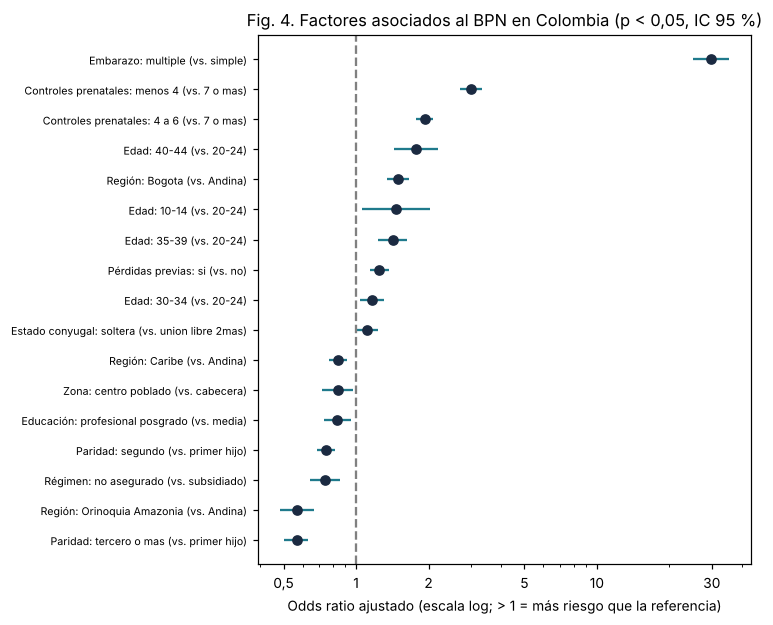

In [16]:
NOMBRE_VAR = {"edad_madre": "Edad", "educacion": "Educación", "zona": "Zona", "regimen": "Régimen",
              "estado_conyugal": "Estado conyugal", "etnia": "Etnia", "region": "Región",
              "embarazo_multiple": "Embarazo", "paridad": "Paridad", "perdidas_previas": "Pérdidas previas",
              "controles": "Controles prenatales"}
def etiqueta(col):
    var = next(v for v in NOMBRE_VAR if col.startswith(v + "_"))
    ref = next(r for r in refs if r.startswith(var + "_"))[len(var) + 1:]
    return f"{NOMBRE_VAR[var]}: {col[len(var)+1:].replace('_', ' ')} (vs. {ref.replace('_', ' ')})"
o = OR_tab[OR_tab.p < 0.05].sort_values("OR").copy(); o.index = [etiqueta(c) for c in o.index]
fig, ax = plt.subplots(figsize=(7, 0.28 * len(o) + 1))
ax.errorbar(o.OR, range(len(o)), xerr=[o.OR - o["IC95 inf"], o["IC95 sup"] - o.OR], fmt="o", c="#1B2A41", ecolor="#1F7A8C")
ax.axvline(1, c="gray", ls="--"); ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index, fontsize=7)
ax.set_xscale("log"); ax.set_xticks([0.5, 1, 2, 5, 10, 30]); ax.set_xticklabels(["0,5", "1", "2", "5", "10", "30"])
ax.set_xlabel("Odds ratio ajustado (escala log; > 1 = más riesgo que la referencia)")
ax.set_title("Fig. 4. Factores asociados al BPN en Colombia (p < 0,05, IC 95 %)")
plt.tight_layout(); plt.savefig(RES + "fig4_odds_ratios.png", dpi=200); plt.show()

**Lectura de la Tabla 6 y la Fig. 4** (odds ratios ajustados: cada uno compara con la categoría de referencia, manteniendo fijas las demás variables):
* **Embarazo múltiple** multiplica las odds de BPN por unas 30: es, por lejos, el factor más fuerte.
* **Controles prenatales:** menos de 4 controles triplica las odds (OR 3,0) y 4–6 controles las casi duplican (OR 1,9) frente a 7 o más. Hay un gradiente: a menos controles, más riesgo.
* **Bogotá** tiene 1,5 veces las odds de la región Andina aun ajustando por todo lo demás. Es consistente con el efecto de la **altitud** (2.600 m) sobre el crecimiento fetal descrito en la literatura (López-Camelo *et al.*, 2006).
* **Edad de la madre:** riesgo mayor en los extremos (10–14 años, OR 1,5; 35–39, 1,4; 40–44, 1,8).
* **Primer hijo** y **pérdidas previas** (OR 1,25) aumentan el riesgo; el segundo hijo (0,75) y el tercero o más (0,57) lo reducen frente al primero.
* Educación, zona, régimen y etnia tienen efectos pequeños una vez se ajusta por lo anterior. Dos resultados contraintuitivos (no asegurado 0,74 y Orinoquía-Amazonía 0,57) **no deben leerse como protección**: pueden reflejar diferencias en quién queda registrado y en la calidad del registro del peso en zonas apartadas.

In [17]:
art = pd.DataFrame({
    "factor del artículo": ["Menos de 4 controles prenatales", "Sin consejería nutricional", "MUAC < 23 cm (desnutrición materna)",
                            "Estrés durante el embarazo"],
    "OR Feyisa et al. (Etiopía)": ["2,8 (1,12–6,82)", "2,4 (1,24–4,72)", "3,1 (1,64–5,91)", "2,8 (1,23–6,36)"],
    "OR en Colombia (DANE 2022)": [f"{OR_tab.loc['controles_menos_4','OR']:.2f} ({OR_tab.loc['controles_menos_4','IC95 inf']:.2f}–{OR_tab.loc['controles_menos_4','IC95 sup']:.2f})",
                                   "no registrado por el DANE", "no registrado por el DANE", "no registrado por el DANE"],
})
art.to_csv(RES + "tabla7_contraste_articulo.csv", index=False); print(art.to_string(index=False))

                factor del artículo OR Feyisa et al. (Etiopía) OR en Colombia (DANE 2022)
    Menos de 4 controles prenatales            2,8 (1,12–6,82)           3.01 (2.71–3.35)
         Sin consejería nutricional            2,4 (1,24–4,72)  no registrado por el DANE
MUAC < 23 cm (desnutrición materna)            3,1 (1,64–5,91)  no registrado por el DANE
         Estrés durante el embarazo            2,8 (1,23–6,36)  no registrado por el DANE


**Lectura de la Tabla 7.** De los cuatro factores del artículo, solo uno se puede medir con datos colombianos, y **se reproduce**: menos de 4 controles prenatales tiene OR 3,0 en Colombia frente a 2,8 en Etiopía, con un intervalo mucho más estrecho (por el tamaño de la muestra, 39.618 frente a 324). Los otros tres (consejería nutricional, perímetro braquial y estrés) no se registran en el certificado de nacido vivo, así que no se pueden confirmar ni descartar. Lo que cambia en el contexto local son los factores que el artículo no podía ver: embarazo múltiple, altitud (Bogotá) y edades extremas.

## 7. Análisis de sensibilidad
**(a) Sin controles prenatales.** El número de controles depende en parte de cuánto duró el embarazo (un bebé prematuro alcanza a tener menos controles), y la prematurez es la principal causa de BPN. Si la asociación fuera solo eso, al quitar la variable el modelo perdería casi todo. Se repite la validación del modelo final sin esa variable.

**(b) Solo embarazos simples.** El embarazo múltiple es un factor tan fuerte que podría dominar el modelo; se reestiman los odds ratios solo con embarazos simples.

In [18]:
sin_ctrl = [c for c in X.columns if c != "controles"]
r_sc = cross_validate(estimador(FINAL), Xtr[sin_ctrl], ytr, cv=cv_ext, scoring=METRICAS)
sens = pd.DataFrame({
    "versión": ["con controles (modelo final)", "sin controles prenatales"],
    "PR-AUC media": [t.loc[FINAL, "PR_AUC_media"], r_sc["test_pr_auc"].mean()],
    "PR-AUC DE": [t.loc[FINAL, "PR_AUC_de"], r_sc["test_pr_auc"].std()],
    "ROC-AUC media": [t.loc[FINAL, "ROC_AUC_media"], r_sc["test_roc_auc"].mean()],
}).round(4)
sens.to_csv(RES + "tabla8_sensibilidad.csv", index=False); print(sens.to_string(index=False))

simples = (Xtr.embarazo_multiple == "simple").values
OR_simple, _ = tabla_or(Xtr[simples].reset_index(drop=True), ytr[simples], [c for c in X.columns if c != "embarazo_multiple"])
comp = OR_tab.join(OR_simple, rsuffix=" (solo simples)", how="inner")[["OR", "OR (solo simples)"]]
comp.to_csv(RES + "tabla9_or_solo_simples.csv"); print(comp.sort_values("OR", ascending=False).to_string())

                     versión  PR-AUC media  PR-AUC DE  ROC-AUC media
con controles (modelo final)        0.2733     0.0121         0.6746
    sin controles prenatales        0.2484     0.0134         0.6272


                                       OR  OR (solo simples)
controles_menos_4                   3.009              3.051
controles_4_a_6                     1.928              1.933
edad_madre_40-44                    1.779              1.862
region_Bogota                       1.490              1.495
edad_madre_45+                      1.488              1.619
edad_madre_10-14                    1.461              1.458
edad_madre_35-39                    1.421              1.464
perdidas_previas_si                 1.251              1.261
edad_madre_30-34                    1.164              1.184
estado_conyugal_soltera             1.113              1.087
regimen_excepcion_especial          1.111              1.103
edad_madre_25-29                    1.071              1.081
regimen_contributivo                1.064              1.058
educacion_primaria_o_menos          1.039              1.047
estado_conyugal_union_libre_menos2  1.028              1.022
estado_conyugal_casada  

**Lectura.** (a) Sin controles prenatales la PR-AUC baja de 0,273 a 0,248 y la ROC-AUC de 0,675 a 0,627: la variable aporta, pero el modelo sigue 2,4 veces por encima del azar, así que no todo depende de ella. Parte del efecto de los controles puede deberse a la prematurez, por lo que su OR no debe leerse como causal. (b) Con solo embarazos simples los odds ratios casi no cambian (menos de 4 controles: 3,05 frente a 3,01; Bogotá: 1,50 frente a 1,49): las conclusiones no dependen del embarazo múltiple.

## 8. Reproducibilidad
Semilla 42 en partición, validación cruzada, bootstrap y muestra. Todas las tablas (`tabla*.csv`) y figuras (`fig*.png`) del informe están en `resultados/` y salen de este cuaderno.

In [19]:
print(sorted(os.listdir(RES)))

['curvas_validacion.csv', 'cv_por_pliegue.csv', 'fig1_estabilidad_cv.png', 'fig2_curvas_validacion.png', 'fig3_prueba_final.png', 'fig4_odds_ratios.png', 'matriz_confusion.csv', 'tabla1_descriptivo.csv', 'tabla2_comparacion_cv.csv', 'tabla3_prueba_final.csv', 'tabla4_quintiles_riesgo.csv', 'tabla5_perfil_errores.csv', 'tabla6_odds_ratios.csv', 'tabla7_contraste_articulo.csv', 'tabla8_sensibilidad.csv', 'tabla9_or_solo_simples.csv', 'verificacion_L1_L2.csv']
